# Quantum Convolutional Neural Networks (QCNN)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mateo-Giacometti/tp_computacion_cuantica/blob/main/qcnn/notebooks/qcnn.ipynb)

En este notebook se desarrolla la sección dedicada a **Quantum Convolutional Neural Networks (QCNN)** del trabajo práctico de Computación Cuántica sobre Quantum Machine Learning. Siguiendo exactamente la arquitectura presentada en las diapositivas de la sección 4 ([Cong, Choi y Lukin, 2019](https://arxiv.org/abs/1810.03787)), implementamos una QCNN de $8 \to 4 \to 2 \to 1$ qubits en [PennyLane](https://docs.pennylane.ai/) y la evaluamos en sus dos escenarios más estudiados en la literatura: reconocimiento de fases cuánticas (cuadrante **QQ**) y clasificación de dígitos escritos a mano (cuadrante **CQ**).

1. Arquitectura QCNN ($8 \to 4 \to 2 \to 1$ qubits): convolución compartida y pooling
2. Caso de uso nativo (**QQ**): reconocimiento de fases en el modelo de Ising transversal
3. Imágenes clásicas (**CQ**): clasificación de dígitos `0` vs. `1` (`scikit-learn`)
4. Ausencia de *barren plateaus* y mirada crítica

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/tp_computacion_cuantica")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Mateo-Giacometti/tp_computacion_cuantica.git", str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)
    if importlib.util.find_spec("pennylane") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pennylane>=0.45"], check=True)
    BASE_DIR = REPO_DIR / "qcnn"
else:
    BASE_DIR = Path("..").resolve()

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.linear_model import LogisticRegression
from src import datasets as ds, plots as pl

FIGURES_DIR = pl.init_environment(BASE_DIR / "figuras")

## 1. Arquitectura QCNN ($8 \to 4 \to 2 \to 1$ qubits)

A diferencia de una QNN genérica, una QCNN traslada las ideas estructurales de las redes convolucionales clásicas al circuito cuántico ([Cong, Choi y Lukin, 2019](https://arxiv.org/abs/1810.03787); [Hur, Kim y Park, 2022](https://arxiv.org/abs/2108.00661)):

- **Convolución cuántica $U(\boldsymbol{\theta}_\ell)$:** la misma compuerta unitaria de 2 qubits (con pesos compartidos) recorre todos los pares vecinos en dos tandas —pares $(0,1),(2,3),\dots$ y corridos $(1,2),(3,4),\dots$ con borde periódico— mezclando la información local sin reducir todavía los qubits. Aquí usamos una compuerta simétrica con `CNOT` en ambos sentidos y rotaciones $R_Y, R_Z$ ($6$ parámetros por etapa).
- **Pooling cuántico $P(\boldsymbol{\phi}_\ell)$:** transfiere información del qubit de control $c$ al qubit objetivo $t$ mediante `CRZ`($\phi_1$), `X` en $c$ y `CRX`($\phi_2$), descartando luego $c$ sin necesidad de mediciones intermedias (principio de medición diferida, $2$ parámetros por etapa).
- **Escalado logarítmico:** cada etapa reduce los qubits a la mitad ($8 \to 4 \to 2 \to 1$), por lo que para $n = 8$ qubits hay $\log_2 8 = 3$ etapas y apenas **$3 \times (6 + 2) = 24$ parámetros entrenables** en total ($\mathcal{O}(\log n)$). La predicción final es el valor esperado $\langle Z_7 \rangle \in [-1, 1]$ en el único qubit sobreviviente.

Etapas: 3 (log2 8) | Parámetros totales: 24


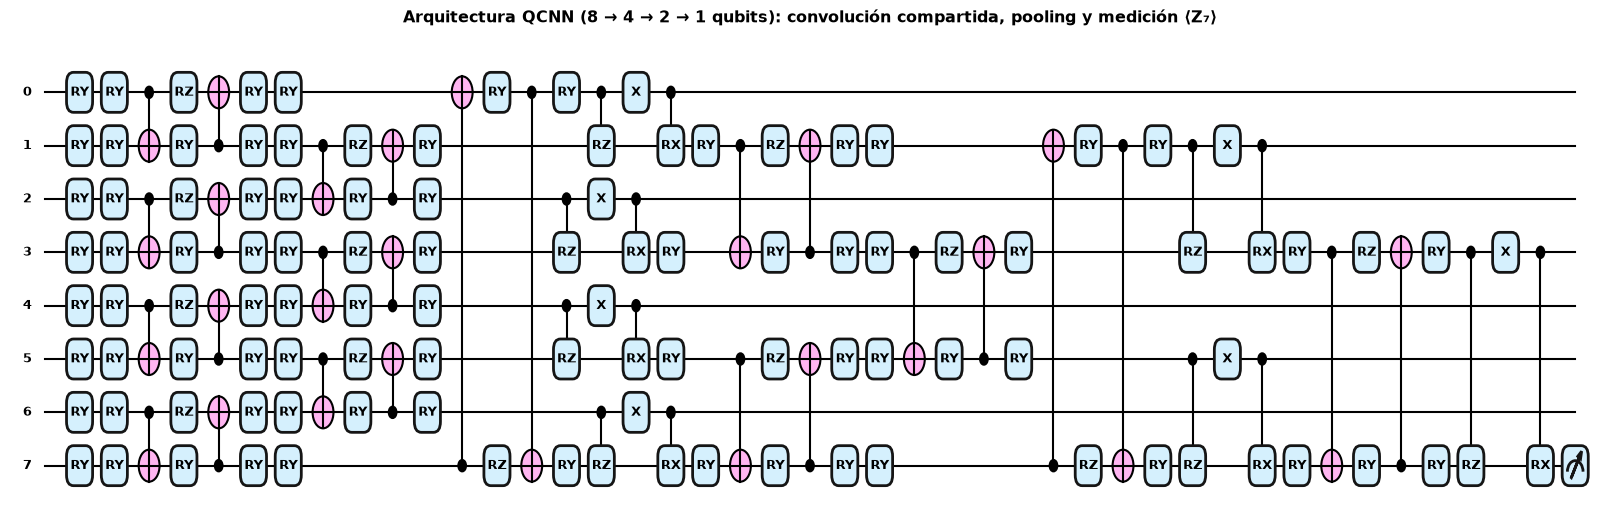

In [2]:
def conv_gate(params, w0, w1):
    # Compuerta convolucional de 2 qubits con CNOT bidireccional (6 parámetros)
    qml.RY(params[0], wires=w0)
    qml.RY(params[1], wires=w1)
    qml.CNOT(wires=[w0, w1])
    qml.RZ(params[2], wires=w0)
    qml.RY(params[3], wires=w1)
    qml.CNOT(wires=[w1, w0])
    qml.RY(params[4], wires=w0)
    qml.RY(params[5], wires=w1)


def pool_gate(params, control, target):
    # Pooling cuántico de las diapositivas: CRZ(phi1), X en control, CRX(phi2)
    qml.CRZ(params[0], wires=[control, target])
    qml.PauliX(wires=control)
    qml.CRX(params[1], wires=[control, target])


def qcnn_body(conv_params, pool_params, n_qubits=8):
    active = list(range(n_qubits))
    stage = 0
    while len(active) > 1:
        k = len(active)
        # Tanda A: pares contiguos
        for i in range(0, k, 2):
            conv_gate(conv_params[stage], active[i], active[i + 1])
        # Tanda B: pares corridos con borde periódico
        if k > 2:
            for i in range(1, k, 2):
                conv_gate(conv_params[stage], active[i], active[(i + 1) % k])
        # Pooling: la mitad transfiere su información y se descarta
        for i in range(0, k, 2):
            pool_gate(pool_params[stage], active[i], active[i + 1])
        active = active[1::2]
        stage += 1
    return active[0]


dev8 = qml.device("default.qubit", wires=8)


@qml.qnode(dev8, interface="autograd")
def qcnn_angle_demo(x, conv_p, pool_p):
    for i in range(8):
        qml.RY(np.pi * x[i], wires=i)
    out_wire = qcnn_body(conv_p, pool_p, n_qubits=8)
    return qml.expval(qml.PauliZ(out_wire))


c_demo = np.zeros((3, 6))
p_demo = np.zeros((3, 2))
print(f"Etapas: {len(c_demo)} (log2 8) | Parámetros totales: {c_demo.size + p_demo.size}")
pl.plot_qcnn_circuit(qcnn_angle_demo, np.linspace(0.1, 0.8, 8), c_demo, p_demo, FIGURES_DIR / "01_circuito_qcnn.png")

## 2. Caso de uso nativo (cuadrante QQ): fases de la materia en el modelo de Ising

El trabajo original de [Cong, Choi y Lukin (2019)](https://arxiv.org/abs/1810.03787) diseñó la QCNN para reconocer **fases cuánticas de la materia** leyendo el estado del sistema físico directamente, sin necesidad de codificar datos clásicos (*cuadrante QQ*).

Consideramos una cadena periódica de $N = 8$ espines descrita por el **modelo de Ising con campo transversal (TFIM)**:

$$H(h) = -\sum_{i=0}^{7} Z_i Z_{i+1} - h \sum_{i=0}^{7} X_i$$

El estado fundamental $|\psi_0(h)\rangle \in \mathbb{C}^{256}$ exhibe una transición de fase cuántica en $h_c = 1$: para $h < 1$ predomina el acoplamiento ferromagnético (**fase ordenada**, etiqueta $+1$) y para $h > 1$ domina el campo transversal (**fase desordenada**, etiqueta $-1$). Entrenamos la QCNN con apenas **12 estados cuánticos** lejos de la transición ($h \le 0.65$ y $h \ge 1.35$, sin mostrarle nunca la zona crítica) y evaluamos su predicción $\langle Z_7 \rangle(h)$ en toda la curva $h \in [0.1, 2.0]$.

Pérdida final MSE (12 estados de train): 0.0963
Salida en fase ordenada (h=0.10): +0.742 | fase desordenada (h=2.00): -0.810
Transición detectada por la QCNN (cruce por 0): h ≈ 0.934  (teórico en N → ∞: h_c = 1.000)


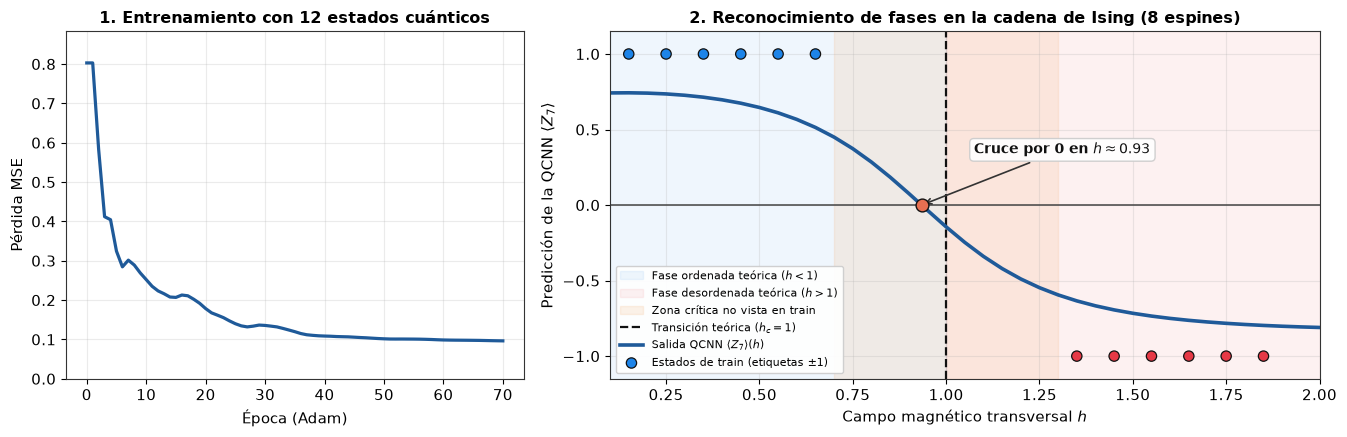

In [3]:
hs_train, states_train, y_train_iso, hs_grid, states_grid = ds.make_tfim_dataset(n_spins=8)
X_tr_iso = pnp.array(states_train, requires_grad=False)
y_tr_iso = pnp.array(y_train_iso, requires_grad=False)


@qml.qnode(dev8, interface="autograd")
def qcnn_ising(states, conv_p, pool_p):
    # Cuadrante QQ: el estado cuántico entra directo al circuito, sin codificación clásica
    qml.StatePrep(states, wires=range(8))
    out_wire = qcnn_body(conv_p, pool_p, n_qubits=8)
    return qml.expval(qml.PauliZ(out_wire))


rng = np.random.default_rng(7)
cp_iso = pnp.array(rng.uniform(-0.8, 0.8, size=(3, 6)), requires_grad=True)
pp_iso = pnp.array(rng.uniform(-0.8, 0.8, size=(3, 2)), requires_grad=True)
opt_iso = qml.AdamOptimizer(stepsize=0.12)

loss_iso = lambda c, p: pnp.mean((qcnn_ising(X_tr_iso, c, p) - y_tr_iso) ** 2)
losses_iso = [float(loss_iso(cp_iso, pp_iso))]
for _ in range(70):
    (cp_iso, pp_iso), lv = opt_iso.step_and_cost(loss_iso, cp_iso, pp_iso)
    losses_iso.append(float(lv))

preds_grid = np.asarray(qcnn_ising(states_grid, cp_iso, pp_iso))
cross_idx = np.where(np.diff(np.sign(preds_grid)))[0]
crossing_h = (
    float(hs_grid[cross_idx[0]] - preds_grid[cross_idx[0]] * (hs_grid[cross_idx[0] + 1] - hs_grid[cross_idx[0]]) / (preds_grid[cross_idx[0] + 1] - preds_grid[cross_idx[0]]))
    if len(cross_idx) > 0
    else None
)

print(f"Pérdida final MSE (12 estados de train): {losses_iso[-1]:.4f}")
print(f"Salida en fase ordenada (h=0.10): {preds_grid[0]:+.3f} | fase desordenada (h=2.00): {preds_grid[-1]:+.3f}")
print(f"Transición detectada por la QCNN (cruce por 0): h ≈ {crossing_h:.3f}  (teórico en N → ∞: h_c = 1.000)")

pl.plot_ising_phase_transition(
    losses_iso, hs_train, y_train_iso, hs_grid, preds_grid, crossing_h,
    FIGURES_DIR / "02_fases_ising_qcnn.png",
)

## 3. Imágenes clásicas (cuadrante CQ): dígitos `0` vs. `1`

En la literatura aplicada a datos clásicos ([Hur, Kim y Park, 2022](https://arxiv.org/abs/2108.00661)), las QCNN se evalúan frecuentemente sobre tareas binarias de dígitos escritos a mano (MNIST o los dígitos $8 \times 8$ de `scikit-learn`). Como codificar un píxel por qubit exigiría demasiados qubits ($28 \times 28 = 784$ en MNIST completo, o $16$ qubits si se reduce a $4 \times 4$), una estrategia estándar en 8 qubits consiste en comprimir cada dígito a 8 componentes principales (PCA) escaladas a $[0, 1]$ y cargarlas con $R_Y(\pi x_i)$.

Reutilizamos **exactamente la misma QCNN de 24 parámetros** entrenada con solo 60 imágenes (en línea con las cotas de generalización con pocos datos de [Caro et al., 2022](https://arxiv.org/abs/2111.05292)) y la comparamos de forma honesta frente a una Regresión Logística clásica sobre las mismas 8 características.

Precisión en test (dígitos 0 vs. 1) | QCNN (8 qubits, 24 params): 92.6%
Precisión en test (dígitos 0 vs. 1) | Regresión Logística clásica: 100.0%


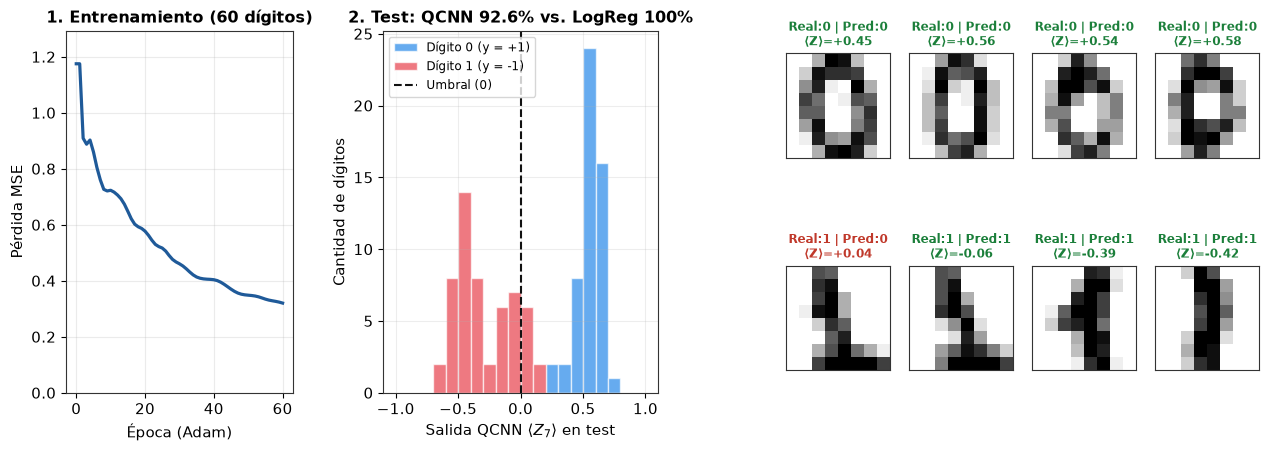

In [4]:
X_tr_d, X_te_d, y_tr_d, y_te_d, img_te_d = ds.load_digits_01_pca8(n_train=60, seed=42)
X_tr_dp = pnp.array(X_tr_d, requires_grad=False)
y_tr_dp = pnp.array(y_tr_d, requires_grad=False)


@qml.qnode(dev8, interface="autograd")
def qcnn_digits(X_batch, conv_p, pool_p):
    # Cuadrante CQ: las 8 features PCA entran como ángulos RY(pi * x_i)
    for i in range(8):
        qml.RY(np.pi * X_batch[:, i], wires=i)
    out_wire = qcnn_body(conv_p, pool_p, n_qubits=8)
    return qml.expval(qml.PauliZ(out_wire))


rng_d = np.random.default_rng(7)
cp_d = pnp.array(rng_d.uniform(-0.8, 0.8, size=(3, 6)), requires_grad=True)
pp_d = pnp.array(rng_d.uniform(-0.8, 0.8, size=(3, 2)), requires_grad=True)
opt_d = qml.AdamOptimizer(stepsize=0.12)

loss_d = lambda c, p: pnp.mean((qcnn_digits(X_tr_dp, c, p) - y_tr_dp) ** 2)
losses_d = [float(loss_d(cp_d, pp_d))]
for _ in range(60):
    (cp_d, pp_d), lv_d = opt_d.step_and_cost(loss_d, cp_d, pp_d)
    losses_d.append(float(lv_d))

preds_te_d = np.asarray(qcnn_digits(X_te_d, cp_d, pp_d))
acc_qcnn = float(np.mean(np.sign(preds_te_d) == y_te_d))
acc_logreg = float(LogisticRegression().fit(X_tr_d, y_tr_d).score(X_te_d, y_te_d))

print(f"Precisión en test (dígitos 0 vs. 1) | QCNN (8 qubits, 24 params): {acc_qcnn:.1%}")
print(f"Precisión en test (dígitos 0 vs. 1) | Regresión Logística clásica: {acc_logreg:.1%}")

pl.plot_digits_results(
    losses_d, img_te_d, y_te_d, preds_te_d, acc_qcnn, acc_logreg,
    FIGURES_DIR / "03_digitos_qcnn.png",
)

## 4. Ausencia de *barren plateaus* y mirada crítica

Una propiedad teórica central demostrada por [Pesah et al. (2021)](https://arxiv.org/abs/2011.02966) es que **las QCNN no sufren *barren plateaus***: al medir un único qubit tras solo $\log_2 n$ etapas locales, la varianza del gradiente cae a lo sumo polinomialmente ($1/\operatorname{poly}(n)$) en lugar de exponencialmente ($2^{-n}$) como en una QNN genérica.

A continuación verificamos este contraste empíricamente comparando la varianza de $\partial f / \partial \theta$ de nuestra QCNN ($n = 2, 4, 8$) frente a la QNN de paridad de la sección anterior ($n = 2, 4, 6, 8, 10$). Sin embargo, como señalan [Bermejo et al. (2024)](https://arxiv.org/abs/2408.12739) y [Bowles, Ahmed y Schuld (2024)](https://arxiv.org/abs/2403.07059), la misma localidad que hace entrenable a la QCNN permite simularla clásicamente en muchos benchmarks y en imágenes clásicas no supera a los modelos tradicionales; su mayor valor está en el procesamiento nativo de datos cuánticos.

n =  2 qubits | Var[QCNN] = 1.39e-01 | Var[QNN genérica] = 6.68e-02 | razón = 2x
n =  4 qubits | Var[QCNN] = 1.54e-01 | Var[QNN genérica] = 2.48e-03 | razón = 62x
n =  8 qubits | Var[QCNN] = 1.90e-02 | Var[QNN genérica] = 1.44e-05 | razón = 1,313x


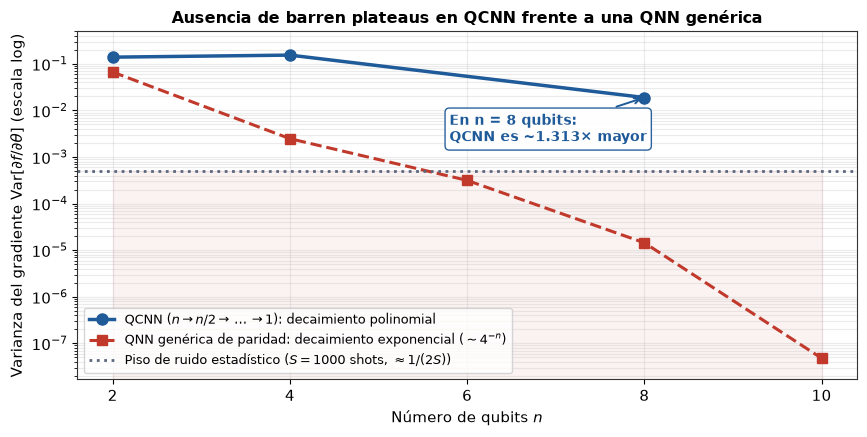

In [5]:
rng_bp = np.random.default_rng(123)
qcnn_ns = [2, 4, 8]
qnn_ns = [2, 4, 6, 8, 10]
shots_ref = 1000
qcnn_vars, qnn_vars = [], []

for n_q in qcnn_ns:
    n_stages = int(np.log2(n_q))
    dev_n = qml.device("default.qubit", wires=n_q)

    @qml.qnode(dev_n, interface="autograd")
    def qcnn_single(x_s, c_p, p_p):
        for i in range(n_q):
            qml.RY(x_s[i], wires=i)
        out_w = qcnn_body(c_p, p_p, n_qubits=n_q)
        return qml.expval(qml.PauliZ(out_w))

    grads = []
    for _ in range(50):
        xs = pnp.array(rng_bp.uniform(0, 2 * np.pi, size=n_q), requires_grad=False)
        c_r = pnp.array(rng_bp.uniform(0, 2 * np.pi, size=(n_stages, 6)), requires_grad=True)
        p_r = pnp.array(rng_bp.uniform(0, 2 * np.pi, size=(n_stages, 2)), requires_grad=False)
        grads.append(float(qml.grad(qcnn_single, argnums=1)(xs, c_r, p_r)[0, 0]))
    qcnn_vars.append(float(np.var(grads)))

for n_q in qnn_ns:
    dev_n = qml.device("default.qubit", wires=n_q)

    @qml.qnode(dev_n)
    def qnn_parity_batch(x_b, th_b):
        for i in range(n_q):
            qml.RX(x_b[:, i], wires=i)
            qml.RY(th_b[:, i], wires=i)
        for i in range(n_q - 1):
            qml.CNOT(wires=[i, i + 1])
        return qml.expval(qml.PauliZ(n_q - 1))

    x_b = rng_bp.uniform(0, 2 * np.pi, size=(120, n_q))
    th_b = rng_bp.uniform(0, 2 * np.pi, size=(120, n_q))
    th_p, th_m = th_b.copy(), th_b.copy()
    th_p[:, 0] += np.pi / 2
    th_m[:, 0] -= np.pi / 2
    g_qnn = 0.5 * (np.asarray(qnn_parity_batch(x_b, th_p)) - np.asarray(qnn_parity_batch(x_b, th_m)))
    qnn_vars.append(float(np.var(g_qnn)))

for n_q, vq in zip(qcnn_ns, qcnn_vars):
    vg = qnn_vars[qnn_ns.index(n_q)]
    print(f"n = {n_q:2d} qubits | Var[QCNN] = {vq:.2e} | Var[QNN genérica] = {vg:.2e} | razón = {vq / vg:,.0f}x")

pl.plot_barren_plateau_comparison(
    qcnn_ns, qcnn_vars, qnn_ns, qnn_vars, 1.0 / (2 * shots_ref), shots_ref,
    FIGURES_DIR / "04_ausencia_barren_plateaus.png",
)

## Referencias

1. Bermejo, P., Braccia, P., Rudolph, M. S., Holmes, Z., Cincio, L. y Cerezo, M. (2024). *Quantum convolutional neural networks are (effectively) classically simulable*. [arXiv:2408.12739](https://arxiv.org/abs/2408.12739)
2. Bowles, J., Ahmed, S. y Schuld, M. (2024). *Better than classical? The subtle art of benchmarking quantum machine learning models*. [arXiv:2403.07059](https://arxiv.org/abs/2403.07059)
3. Caro, M. C., Huang, H.-Y., Cerezo, M., Sharma, K., Sornborger, A., Cincio, L. y Coles, P. J. (2022). *Generalization in quantum machine learning from few training data*. Nature Communications, 13, 4919. [arXiv:2111.05292](https://arxiv.org/abs/2111.05292)
4. Cong, I., Choi, S. y Lukin, M. D. (2019). *Quantum convolutional neural networks*. Nature Physics, 15, 1273–1278. [arXiv:1810.03787](https://arxiv.org/abs/1810.03787)
5. Hur, T., Kim, L. y Park, D. K. (2022). *Quantum convolutional neural network for classical data classification*. Quantum Machine Intelligence, 4, 3. [arXiv:2108.00661](https://arxiv.org/abs/2108.00661)
6. Pesah, A., Cerezo, M., Wang, S., Volkoff, T., Sornborger, A. T. y Coles, P. J. (2021). *Absence of barren plateaus in quantum convolutional neural networks*. Physical Review X, 11, 041011. [arXiv:2011.02966](https://arxiv.org/abs/2011.02966)
7. Vatan, F. y Williams, C. (2004). *Optimal quantum circuits for general two-qubit gates*. Physical Review A, 69, 032315. [arXiv:quant-ph/0308006](https://arxiv.org/abs/quant-ph/0308006)